# Qismet: can QAOA propose useful neural subnetworks?

**An executed, reproducible feasibility experiment — not a claim of quantum advantage.**

We train a small PyTorch classifier, structurally remove hidden neurons, rewind surviving
weights to their **original initialization**, and retrain. We then learn a quadratic
approximation to validation loss after retraining and use **Qiskit QAOA on a noiseless
CPU statevector simulator** to propose masks. No quantum account or hardware is required.

The supported input is one architecture: **2 → 8 tanh → 2 logits**, on a fixed two-moons
classification dataset. Change the pruning percentage below; the retained count is rounded
to the nearest integer (halves round up). Arbitrary neural networks are deliberately unsupported.

The default experiment has three fixed initializations, 50% hidden-neuron pruning, 200 full-batch
Adam steps per training run, and 32 final QAOA shots. The code is self-contained in this notebook.
Run all cells from top to bottom. It writes reproducibility artifacts to `results/` beside it.

**What counts as evidence?** A selected mask must retrain well on untouched test data.
We separately measure whether the surrogate predicts unseen-mask performance and whether
QAOA favors good masks *within the correct pruning budget*. None is assumed to succeed.

## Setup and fixed protocol

Install the accompanying requirements in a Python environment, then select that environment
as the notebook kernel. The saved notebook already includes outputs from an actual execution.
The configuration is declared before any test results are inspected. Three initialization seeds
share the same data split; they do not measure uncertainty across datasets or establish significance.

In [1]:
import sys, json, time, importlib.metadata
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HIDDEN = 8
PRUNING_PERCENTAGE = 50
EPOCHS = 200
INITIALIZATION_SEEDS = [11, 22, 33]
SHOTS = 32
RESULT_DIR = Path('results')
RESULT_DIR.mkdir(exist_ok=True)
VERSIONS = {name: importlib.metadata.version(name) for name in
            ['torch', 'numpy', 'scipy', 'scikit-learn', 'qiskit', 'pandas', 'matplotlib']}
print('Python:', sys.version.split()[0])
print(json.dumps(VERSIONS, indent=2))

Python: 3.13.7
{
  "torch": "2.15.0+cpu",
  "numpy": "2.5.4",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "qiskit": "2.6.1",
  "pandas": "3.1.1",
  "matplotlib": "3.11.2"
}


In [2]:
"""Small, deterministic structured-pruning experiment for the Qismet notebook."""
import copy
import json
import time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import spearmanr

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

## 1. Train, prune, rewind, retrain

There are 900 training, 300 validation, and 300 test examples. Standardization is fit on
training examples only. The immutable checkpoint is saved **before dense training**.
Pruning physically slices hidden-layer rows, hidden biases, and output-layer columns.
The output bias is also reset. Every retraining creates a fresh Adam optimizer.

Assertions check exact restoration and equality between the sliced network and the original
network with hidden activations masked. The first milestone reports validation accuracy;
test examples are reserved for the final comparison. Magnitude pruning here ranks the trained
outgoing-weight norms; it is a simple structured-pruning baseline, not iterative magnitude pruning.

In [3]:
class TinyMLP(nn.Module):
    """Supported model: two inputs, one tanh hidden layer, two class logits."""
    def __init__(self, hidden=8):
        super().__init__()
        self.fc1 = nn.Linear(2, hidden)
        self.fc2 = nn.Linear(hidden, 2)

    def forward(self, x):
        return self.fc2(torch.tanh(self.fc1(x)))


def prepare_data(seed=2026, samples=1500):
    x, y = make_moons(n_samples=samples, noise=0.20, random_state=seed)
    xt, xrest, yt, yrest = train_test_split(x, y, test_size=0.4, stratify=y, random_state=seed)
    xv, xe, yv, ye = train_test_split(xrest, yrest, test_size=0.5, stratify=yrest, random_state=seed+1)
    scaler = StandardScaler().fit(xt)  # Never fit preprocessing on validation/test.
    return {name: (torch.tensor(scaler.transform(xx), dtype=torch.float32), torch.tensor(yy, dtype=torch.long))
            for name, xx, yy in [('train', xt, yt), ('val', xv, yv), ('test', xe, ye)]}


def clone_state(model):
    return {k: v.detach().clone() for k, v in model.state_dict().items()}


def rewind_subnetwork(initial, mask):
    mask = np.asarray(mask)
    if mask.ndim != 1 or not np.isin(mask, [0, 1]).all() or len(mask) != initial['fc1.bias'].numel():
        raise ValueError('mask must contain one binary value per hidden neuron')
    indices = torch.tensor(np.flatnonzero(mask), dtype=torch.long)
    if len(indices) == 0:
        raise ValueError('Keep at least one neuron')
    # Constructor randomness is completely overwritten by original surviving weights.
    model = TinyMLP(len(indices))
    expected = {'fc1.weight': initial['fc1.weight'][indices], 'fc1.bias': initial['fc1.bias'][indices],
                'fc2.weight': initial['fc2.weight'][:, indices], 'fc2.bias': initial['fc2.bias']}
    model.load_state_dict(expected)
    assert all(torch.equal(model.state_dict()[k], v) for k, v in expected.items())
    return model


def train(model, data, epochs=200, lr=0.03):
    # Full-batch CPU training: identical examples/order/budget and a fresh optimizer.
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    x, y = data['train']
    history = []
    for _ in range(epochs):
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
    return history


def evaluate(model, split):
    model.eval()
    with torch.no_grad():
        x, y = split
        logits = model(x)
        return {'loss': float(nn.functional.cross_entropy(logits, y)),
                'accuracy': float((logits.argmax(1) == y).float().mean())}


def magnitude_mask(model, keep):
    # Rank trained hidden units by outgoing-weight L2 norm (a simple baseline).
    scores = model.fc2.weight.detach().square().sum(dim=0).sqrt().numpy()
    mask = np.zeros(len(scores), dtype=int)
    mask[np.argsort(scores, kind='stable')[-keep:]] = 1
    return mask


def milestone_one(data, seed=11, hidden=8, keep=4, epochs=200):
    torch.manual_seed(seed)
    dense = TinyMLP(hidden)
    initial = clone_state(dense)
    history = train(dense, data, epochs)
    mask = magnitude_mask(dense, keep)
    sparse = rewind_subnetwork(initial, mask)
    # Structural slicing must equal masking the original dense network's activations.
    original = TinyMLP(hidden)
    original.load_state_dict(initial)
    with torch.no_grad():
        x = data['train'][0][:20]
        gated = original.fc2(torch.tanh(original.fc1(x)) * torch.tensor(mask))
        torch.testing.assert_close(sparse(x), gated)
    sparse_history = train(sparse, data, epochs)
    assert all(torch.equal(initial[k], original.state_dict()[k]) for k in initial)
    rows = []
    for name, net in [('Dense', dense), ('Magnitude + rewind', sparse)]:
        rows.append({'method': name, 'parameters': sum(p.numel() for p in net.parameters()),
                     **{f'val_{k}': v for k, v in evaluate(net, data['val']).items()}})
    # Test remains untouched here. Final test reporting happens after all selections.
    return pd.DataFrame(rows), initial, mask, history, sparse_history

,method,parameters,val_loss,val_accuracy
0,Dense,42,0.155922,0.930000
1,Magnitude + rewind,22,0.156437,0.933333


PASS: exact weight rewind; structural equivalence; immutable initialization.


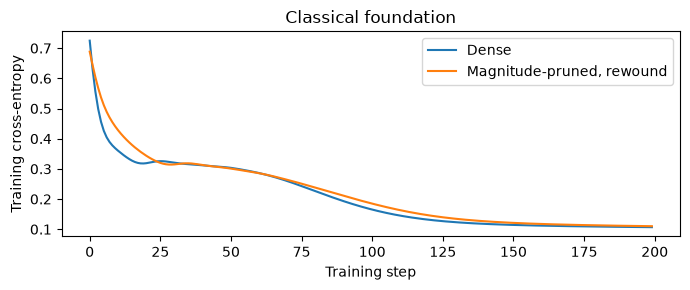

In [4]:
data = prepare_data()
keep = int(np.floor(HIDDEN*(1-PRUNING_PERCENTAGE/100)+0.5))
milestone_table, original_init, first_mask, dense_history, sparse_history = milestone_one(
    data, seed=INITIALIZATION_SEEDS[0], hidden=HIDDEN, keep=keep, epochs=EPOCHS)
torch.save(original_init, RESULT_DIR / 'milestone1_original_initialization.pt')
display(milestone_table)
print('PASS: exact weight rewind; structural equivalence; immutable initialization.')
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(dense_history, label='Dense')
ax.plot(sparse_history, label='Magnitude-pruned, rewound')
ax.set(xlabel='Training step', ylabel='Training cross-entropy', title='Classical foundation')
ax.legend(); fig.tight_layout(); plt.show()

## 2. Define a binary structured-pruning problem

Each of the eight hidden neurons has a binary variable $m_i$: 1 retains it, 0 removes it.
At 50% pruning, $\sum_i m_i=4$: there are 70 feasible masks out of 256 bitstrings.
The dense model has 42 parameters; a four-unit model has 22 (47.6% fewer parameters).

## 3. Fit a QUBO approximation to actual retraining loss

For each initialization we retrain **128 fitting masks** from the saved weights and label
them with validation cross-entropy. Another **48 masks** audit surrogate quality and are
excluded from fitting and hyperparameter selection. At the default budget each set includes
35 distinct four-unit masks. Audit labels are diagnostics; masks remain eligible for search,
but their observed losses never guide QAOA or the classical selectors.

$$\hat L(m)=c+\sum_i a_i m_i+\sum_{i<j} b_{ij}m_i m_j.$$

A ridge regression fits the individual and pairwise effects; 5-fold CV on fitting masks
selects the regularization strength. Terms are **empirical approximations**, not causal
neuron contributions or an exact representation of retraining. We report holdout MAE, $R^2$,
and Spearman rank correlation, especially within the requested pruning budget.
The coefficient convention stores each pair once, in the strict upper triangle.

Collecting retraining labels is the expensive part of this toy demonstration. It may cost
more than directly searching masks; we make no end-to-end acceleration claim.

In [5]:
def all_masks(hidden):
    return ((np.arange(2**hidden)[:, None] >> np.arange(hidden)) & 1).astype(int)


def quadratic_features(masks):
    masks = np.atleast_2d(masks)
    pairs = list(combinations(range(masks.shape[1]), 2))
    return np.column_stack([masks] + [masks[:, i] * masks[:, j] for i, j in pairs])


def label_design(hidden, keep, seed):
    """128 fit masks, up to 48 audit masks, including half of feasible masks each.

    Default n=8,k=4: 35 feasible fit masks + 93 other fit masks;
    35 feasible audit masks + 13 other audit masks. No observed labels guide this split.
    """
    masks = all_masks(hidden)
    rng = np.random.default_rng(seed)
    feasible = rng.permutation(np.flatnonzero(masks.sum(1) == keep))
    other = rng.permutation(np.flatnonzero((masks.sum(1) != keep) & (masks.sum(1) > 0)))
    cut = max(1, len(feasible)//2)
    fit_feasible = feasible[:min(cut, 64)]
    audit_feasible = feasible[cut:cut+35]
    other_fit_n = min(128-len(fit_feasible), max(1, len(other)-13))
    fitting = np.r_[fit_feasible, other[:other_fit_n]]
    audit = np.r_[audit_feasible, other[other_fit_n:other_fit_n+max(0, 48-len(audit_feasible))]]
    assert not set(fitting) & set(audit)
    return masks, fitting, audit


def surrogate_metrics(true, predicted):
    return {'mae': float(mean_absolute_error(true, predicted)),
            'r2': float(r2_score(true, predicted)) if len(true) > 1 else float('nan'),
            'spearman': float(spearmanr(true, predicted).statistic) if len(true) > 1 else float('nan'),
            'n_masks': len(true)}


def fit_surrogate(initial, data, keep, seed, epochs=200):
    hidden = len(initial['fc1.bias'])
    masks, fit_ids, audit_ids = label_design(hidden, keep, seed)
    labels = {}
    start = time.perf_counter()
    for idx, state in enumerate(np.r_[fit_ids, audit_ids]):
        subnet = rewind_subnetwork(initial, masks[state])
        train(subnet, data, epochs)
        labels[int(state)] = evaluate(subnet, data['val'])['loss']
        if (idx+1) % 40 == 0:
            print(f'  seed {seed}: retrained {idx+1}/{len(fit_ids)+len(audit_ids)} masks', flush=True)
    features = quadratic_features(masks)
    # Hyperparameter selection sees fit masks only; audit masks never tune the model.
    cv = KFold(n_splits=5, shuffle=True, random_state=seed)
    search = GridSearchCV(Ridge(), {'alpha': [0.0001, 0.01, 0.1, 1.0, 10.0]},
                          scoring='neg_mean_squared_error', cv=cv)
    search.fit(features[fit_ids], [labels[int(i)] for i in fit_ids])
    reg = search.best_estimator_
    predictions = reg.predict(features)
    audit_y = np.array([labels[int(i)] for i in audit_ids])
    in_budget = masks[audit_ids].sum(1) == keep
    quality = {'all_audit': surrogate_metrics(audit_y, predictions[audit_ids]),
               'feasible_audit': surrogate_metrics(audit_y[in_budget], predictions[audit_ids][in_budget]),
               'ridge_alpha': float(reg.alpha), 'fit_retrains': len(fit_ids), 'audit_retrains': len(audit_ids),
               'label_seconds': time.perf_counter()-start}
    linear = reg.coef_[:hidden].copy()
    pairwise = np.zeros((hidden, hidden))
    for coefficient, (i, j) in zip(reg.coef_[hidden:], combinations(range(hidden), 2)):
        pairwise[i, j] = coefficient
    direct = reg.intercept_ + masks @ linear + np.einsum('bi,ij,bj->b', masks, pairwise, masks)
    np.testing.assert_allclose(predictions, direct, atol=1e-10)
    label_table = pd.DataFrame([{'state': int(i), 'mask': ''.join(map(str, masks[i])),
                                'split': 'fit' if i in set(fit_ids) else 'audit',
                                'kept': int(masks[i].sum()), 'val_loss': labels[int(i)],
                                'predicted_val_loss': float(predictions[i])} for i in np.r_[fit_ids, audit_ids]])
    return linear, pairwise, float(reg.intercept_), predictions, quality, label_table

## 4. Convert to Ising and run QAOA in Qiskit

Add a cardinality penalty:

$$C(m)=\hat L(m)+\lambda(\sum_i m_i-k)^2,\quad
\lambda=1+\sum_i|a_i|+\sum_{i<j}|b_{ij}|.$$

This sufficient penalty exceeds the maximum possible range of the unpenalized surrogate.
It guarantees that all feasible masks have lower cost than all infeasible masks, but it can
dominate the useful retraining signal. The diagnostics expose this tradeoff.

Substitute $m_i=(I-Z_i)/2$. If $a'_i=a_i+\lambda(1-2k)$ and
$b'_{ij}=b_{ij}+2\lambda$, then
$J_{ij}=b'_{ij}/4$ and
$h_i=-a'_i/2-\sum_{j\ne i}b'_{\min(i,j),\max(i,j)}/4$.
The constant offset is retained for energy checks and omitted only as a circuit global phase.

The circuit starts in $|+\rangle^{\otimes8}$ and alternates two Ising cost layers with
X mixers. RZ/RZZ/RX angles implement the exponential with the correct factor of two.
Energy is rescaled by the RMS nonconstant Ising energy for angle optimization.
Three seeded COBYLA starts each receive up to 120 objective evaluations. Their exact
statevector expectations are used during optimization; **32 finite shots** are used only
for the final candidate selection. This is an ideal simulation, not a finite-shot hardware benchmark.

The returned mask is the lowest-surrogate-cost feasible **observed** sample. There is no
fallback to an enumerated optimum. All 256 basis energies are checked against the Qiskit
Hamiltonian. `mask[i]` corresponds to qubit i (least-significant bit); printed mask strings
use neuron order, the reverse of ordinary Qiskit bitstrings.

In [6]:
"""Small, auditable Qiskit QAOA solver for a binary quadratic surrogate.

This is a noiseless CPU statevector simulation, not a quantum-hardware run.
The exhaustive arrays below are diagnostic conveniences for tiny examples. They
are also used to evaluate the diagonal expectation exactly; they do not select
the returned mask. Selection is restricted to finite-shot measurement samples.

Qiskit bit order: mask[i] is qubit i, the i-th least-significant bit of a basis
index. Printed Qiskit bitstrings have the reverse order from the mask list.

References:
https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.SparsePauliOp
https://quantum.cloud.ibm.com/docs/en/tutorials/quantum-approximate-optimization-algorithm
"""


import time
import numpy as np
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector


def solve_qaoa(linear, pairwise, constant, keep, seed=17, reps=2,
               restarts=3, maxiter=120, shots=32):
    """Minimize c + sum(a_i m_i) + sum_{i<j}(b_ij m_i m_j), sum(m)=keep.

    ``pairwise`` must be strictly upper triangular, with each interaction given
    ONCE. A symmetric matrix would double-count its off-diagonal entries and is
    rejected. Width is restricted to 1..14 for this exhaustive teaching demo.

    Add lambda*(sum(m)-keep)**2, where lambda=1+sum(abs(a))+sum(abs(b)).
    The unpenalized objective's range is at most the sum of absolute nonconstant
    coefficients, so every infeasible mask costs more than every feasible mask.
    This sufficient penalty can dominate the useful surrogate signal; the
    diagnostics explicitly expose whether QAOA learns anything beyond sparsity.

    The circuit starts in |+>^n, applies p alternating exp(-i gamma H/scale) and
    exp(-i beta sum(X)) layers, and uses COBYLA with seeded independent starts.
    scale is the RMS nonconstant Ising energy under uniform basis sampling,
    sqrt(sum(h**2)+sum(J**2)). The identity offset is omitted from the circuit.
    Optimization uses exact statevector expectations; only final measurement
    uses ``shots``. Restart selection uses penalized expectation, not exact
    optimal-mask knowledge. Selected mask minimizes surrogate among feasible
    observed samples. No feasible sample raises RuntimeError, with no oracle
    fallback or projection to a mask that was not measured.

    Returns a JSON-serializable dict with these keys:
      selected_mask / selected_index / selected_qubit_bitstring: sampled result.
      selected_surrogate / selected_penalized_energy: cost of that result.
      selected_sample_count: how often that exact basis state was measured.
      n / keep / seed / reps / restarts / maxiter / shots: experiment settings.
      penalty / scale: cardinality coefficient and circuit energy scaling.
      ising: offset, linear Z and upper-triangular ZZ coefficients (unscaled).
      pauli_terms: equivalent full unscaled SparsePauliOp as label/coefficient.
      basis_masks / surrogate_energies / energies / probabilities: full arrays
        indexed by little-endian computational-basis integer.
      sampled_indices / counts / feasible_shots / unique_feasible_samples:
        raw finite-shot outcomes and statistics.
      feasible_probability / uniform_feasible_probability: actual and uniform
        probability of satisfying the cardinality constraint.
      exact_feasible_minimum / optimum_feasible_probability: reference optimum
        of the SURROGATE and probability of measuring any tied optimum.
      uniform_optimum_probability / conditional_optimum_probability: optimum
        probability before and after restricting to feasible QAOA samples.
      uniform_conditional_optimum_probability: optimum fraction among feasible
        masks under uniform sampling (a fairer sparsity-controlled comparison).
      feasible_top_decile_threshold / feasible_top_decile_probability /
        conditional_top_decile_probability / uniform_conditional_top_decile_probability:
        low-surrogate tail diagnostics. Include ties at the 10th percentile.
      conditional_surrogate_mean / uniform_feasible_surrogate_mean: expected
        surrogate conditioned on feasibility and its uniform feasible baseline.
      expected_penalized_energy / uniform_penalized_energy: expectation values.
      parameters / optimizer_records / total_evaluations: optimizer evidence.
      checks: maximum encoding error and state expectation agreement, with
        assertion failures raised if either check fails.
      circuit_depth / circuit_gate_counts / elapsed_seconds: resource metadata.

    Exact optimum probabilities are diagnostic, never optimizer objectives.
    """
    started = time.perf_counter()
    a = np.asarray(linear, dtype=float).copy()
    b = np.asarray(pairwise, dtype=float).copy()
    if a.ndim != 1 or not 1 <= len(a) <= 14:
        raise ValueError("linear must have 1..14 entries for this small demo")
    n = len(a)
    if b.shape != (n, n) or not np.allclose(np.tril(b), 0, atol=1e-14):
        raise ValueError("pairwise must be a strictly upper-triangular n*n matrix")
    if not np.isfinite(a).all() or not np.isfinite(b).all() or not np.isfinite(constant):
        raise ValueError("All surrogate coefficients must be finite")
    if int(keep) != keep or not 0 <= keep <= n:
        raise ValueError("keep must be an integer in [0,n]")
    for name, value in [("reps", reps), ("restarts", restarts),
                        ("maxiter", maxiter), ("shots", shots)]:
        if int(value) != value or value < 1:
            raise ValueError(f"{name} must be a positive integer")
    keep, reps, restarts, maxiter, shots = map(int, (keep, reps, restarts, maxiter, shots))
    constant = float(constant)
    ids = np.arange(2**n)
    masks = ((ids[:, None] >> np.arange(n)) & 1).astype(int)
    feasible = masks.sum(axis=1) == keep
    surrogate = constant + masks @ a + np.einsum("bi,ij,bj->b", masks, b, masks)
    penalty = float(1 + np.abs(a).sum() + np.abs(b).sum())
    energies = surrogate + penalty * (masks.sum(axis=1) - keep)**2
    ap = a + penalty * (1 - 2*keep)
    bp = b + 2*penalty*np.triu(np.ones((n, n)), 1)
    cp = constant + penalty*keep**2
    h = -ap/2 - (bp.sum(axis=0) + bp.sum(axis=1))/4
    J = bp/4
    offset = float(cp + ap.sum()/2 + bp.sum()/4)
    scale = float(max(np.sqrt(np.dot(h, h) + np.sum(J**2)), 1e-12))

    terms = [("I"*n, offset)]
    for i in range(n):
        label = ["I"]*n
        label[n-1-i] = "Z"
        terms.append(("".join(label), float(h[i])))
    for i in range(n):
        for j in range(i+1, n):
            label = ["I"]*n
            label[n-1-i] = label[n-1-j] = "Z"
            terms.append(("".join(label), float(J[i, j])))
    operator = SparsePauliOp.from_list(terms)
    # A sparse matrix avoids allocating a dense 2^n by 2^n verification matrix.
    encoded = operator.to_matrix(sparse=True)
    diagonal = np.real(encoded.diagonal())
    encoding_error = float(np.max(np.abs(diagonal - energies)))
    np.testing.assert_allclose(diagonal, energies, atol=1e-9, rtol=1e-10)
    rows, cols = encoded.nonzero()
    assert np.all(rows == cols), "Cost Hamiltonian must be diagonal"
    if feasible.any() and (~feasible).any():
        assert energies[~feasible].min() > energies[feasible].max(), "Penalty guarantee failed"

    def circuit(parameters):
        qc = QuantumCircuit(n)
        qc.h(range(n))
        gammas, betas = parameters[:reps], parameters[reps:]
        for gamma, beta in zip(gammas, betas):
            for i in range(n):
                qc.rz(2*gamma*h[i]/scale, i)
            for i in range(n):
                for j in range(i+1, n):
                    qc.rzz(2*gamma*J[i, j]/scale, i, j)
            qc.rx(2*beta, range(n))
        return qc

    scaled_energies = (energies - offset)/scale
    rng = np.random.default_rng(seed)
    records = []
    global_best_value = np.inf
    global_best_parameters = None
    total_evaluations = 0
    for restart in range(restarts):
        x0 = np.r_[rng.uniform(-np.pi, np.pi, reps), rng.uniform(-np.pi/2, np.pi/2, reps)]
        trace = []
        run_best_value = np.inf
        run_best_parameters = None

        def objective(parameters):
            nonlocal run_best_value, run_best_parameters, total_evaluations
            state = Statevector.from_instruction(circuit(parameters))
            value = float(state.probabilities() @ scaled_energies)
            total_evaluations += 1
            trace.append(value)
            if value < run_best_value:
                run_best_value = value
                run_best_parameters = np.array(parameters, copy=True)
            return value

        result = minimize(objective, x0, method="COBYLA",
                          options={"maxiter": maxiter, "rhobeg": 0.5, "tol": 1e-5})
        records.append({"restart": restart, "initial_parameters": x0.tolist(),
                        "best_parameters": run_best_parameters.tolist(),
                        "best_scaled_expectation": float(run_best_value),
                        "best_penalized_expectation": float(run_best_value*scale + offset),
                        "evaluations": len(trace), "success": bool(result.success),
                        "message": str(result.message), "scaled_trace": trace})
        if run_best_value < global_best_value:
            global_best_value = run_best_value
            global_best_parameters = run_best_parameters.copy()

    final_circuit = circuit(global_best_parameters)
    final_state = Statevector.from_instruction(final_circuit)
    probabilities = final_state.probabilities()
    expected = float(probabilities @ energies)
    state_expectation = float(np.real(final_state.expectation_value(operator)))
    expectation_error = abs(expected - state_expectation)
    np.testing.assert_allclose(expected, state_expectation, atol=1e-8, rtol=1e-10)
    np.testing.assert_allclose(probabilities.sum(), 1, atol=1e-10)
    # Statevector.sample_memory samples the actual circuit distribution, in
    # ordinary Qiskit bitstring order. Parsing int(bits,2) recovers basis ids.
    final_state.seed(seed + 10000)
    bitstrings = final_state.sample_memory(shots)
    sampled_indices = np.array([int(bits, 2) for bits in bitstrings], dtype=int)
    counts = np.bincount(sampled_indices, minlength=2**n)
    feasible_observed = np.flatnonzero((counts > 0) & feasible)
    if not len(feasible_observed):
        raise RuntimeError(f"No feasible mask in {shots} QAOA shots; do not report an oracle fallback")
    # Only sampled states participate in selecting the proposed mask.
    selected = int(feasible_observed[np.argmin(surrogate[feasible_observed])])
    feasible_mass = float(probabilities[feasible].sum())
    exact_min = float(surrogate[feasible].min())
    optimum = feasible & np.isclose(surrogate, exact_min, atol=1e-10, rtol=1e-10)
    optimum_mass = float(probabilities[optimum].sum())
    tail_threshold = float(np.quantile(surrogate[feasible], 0.1))
    tail = feasible & (surrogate <= tail_threshold + 1e-12)
    tail_mass = float(probabilities[tail].sum())
    return {
        "selected_mask": masks[selected].tolist(), "selected_index": selected,
        "selected_qubit_bitstring": format(selected, f"0{n}b"),
        "selected_surrogate": float(surrogate[selected]),
        "selected_penalized_energy": float(energies[selected]),
        "selected_sample_count": int(counts[selected]),
        "n": n, "keep": keep, "seed": int(seed), "reps": reps,
        "restarts": restarts, "maxiter": maxiter, "shots": shots,
        "penalty": penalty, "scale": scale,
        "ising": {"offset": offset, "h": h.tolist(), "J": J.tolist()},
        "pauli_terms": [[label, coefficient] for label, coefficient in terms],
        "basis_masks": masks.tolist(), "surrogate_energies": surrogate.tolist(),
        "energies": energies.tolist(), "probabilities": probabilities.tolist(),
        "sampled_indices": sampled_indices.tolist(),
        "counts": counts.tolist(), "feasible_shots": int(counts[feasible].sum()),
        "unique_feasible_samples": int(len(feasible_observed)),
        "feasible_probability": feasible_mass,
        "uniform_feasible_probability": float(feasible.mean()),
        "exact_feasible_minimum": exact_min,
        "optimum_feasible_probability": optimum_mass,
        "uniform_optimum_probability": float(optimum.mean()),
        "conditional_optimum_probability": optimum_mass / feasible_mass,
        "uniform_conditional_optimum_probability": float(optimum.sum()/feasible.sum()),
        "feasible_top_decile_threshold": tail_threshold,
        "feasible_top_decile_probability": tail_mass,
        "conditional_top_decile_probability": tail_mass / feasible_mass,
        "uniform_conditional_top_decile_probability": float(tail.sum()/feasible.sum()),
        "conditional_surrogate_mean": float(probabilities[feasible] @ surrogate[feasible]/feasible_mass),
        "uniform_feasible_surrogate_mean": float(surrogate[feasible].mean()),
        "expected_penalized_energy": expected,
        "uniform_penalized_energy": float(energies.mean()),
        "parameters": global_best_parameters.tolist(), "optimizer_records": records,
        "total_evaluations": total_evaluations,
        "checks": {"maximum_basis_encoding_error": encoding_error,
                   "state_expectation_error": expectation_error,
                   "penalty_guarantee": True, "selected_mask_was_sampled": True},
        "circuit_depth": final_circuit.depth(),
        "circuit_gate_counts": {str(k): int(v) for k, v in final_circuit.count_ops().items()},
        "elapsed_seconds": float(time.perf_counter() - started),
    }

## 5. Retrain selections and compare on the untouched test set

All selectors use the surrogate or trained dense weights, never test loss. Compare:

- Dense model and trained-magnitude pruning with rewind.
- One uniform feasible random mask.
- Best of 32 uniform feasible masks by surrogate cost (a stronger sparsity-aware baseline).
- Best feasible mask among 32 uniformly random raw bitstrings (same raw candidate budget as QAOA).
- Classical one-out/one-in greedy swap search and exhaustive feasible QUBO optimization.
- QAOA's best feasible measured mask and a fresh randomly initialized four-unit model.

The exact QUBO solution is an oracle for the **surrogate**, not actual retraining performance.
The 32-shot comparisons match final candidate counts, not total compute: QAOA additionally
uses up to 360 exact-statevector objectives; swap search and exhaustive search have their own
evaluation budgets. Repeated retraining is deterministic full-batch CPU training. Fresh weights
control whether retaining the original initialization matters for this architecture.

In [7]:
def swap_search(start_mask, predicted, masks):
    """Deterministic greedy one-out/one-in search, using only the surrogate."""
    current = start_mask.copy()
    weights = 2**np.arange(len(current))
    evaluations = 0
    while True:
        state = int(current @ weights)
        best_state, best_value = state, predicted[state]
        for i in np.flatnonzero(current):
            for j in np.flatnonzero(1-current):
                candidate = state - int(weights[i]) + int(weights[j])
                evaluations += 1
                if predicted[candidate] < best_value-1e-12:
                    best_state, best_value = candidate, predicted[candidate]
        if best_state == state:
            return current, evaluations
        current = masks[best_state].copy()


def run_experiment(model, data, pruning_percentage=50, seed=11, epochs=200, shots=32):
    """Input an UNTRAINED eight-hidden-unit TinyMLP; its current weights are initialization.

    All samples, hyperparameters and seeds are declared before observing test performance.
    This is an exponential toy demo, not support for arbitrary networks.
    """
    if type(model) is not TinyMLP or model.fc1.out_features != 8:
        raise ValueError('Use the supported TinyMLP architecture with eight hidden neurons')
    if not 0 < pruning_percentage < 100:
        raise ValueError('pruning_percentage must be between 0 and 100')
    hidden = model.fc1.out_features
    keep = int(np.floor(hidden*(1-pruning_percentage/100)+0.5))
    if not 1 <= keep < hidden:
        raise ValueError('The requested percentage must retain 1..hidden-1 neurons after rounding')
    start = time.perf_counter()
    initial = clone_state(model)
    dense = copy.deepcopy(model)
    train(dense, data, epochs)
    mag = magnitude_mask(dense, keep)
    linear, pairwise, constant, predicted, quality, labels = fit_surrogate(initial, data, keep, seed, epochs)
    qaoa_start = time.perf_counter()
    quantum = solve_qaoa(linear, pairwise, constant, keep, seed=seed+1000, shots=shots)
    quantum_seconds = time.perf_counter()-qaoa_start
    masks = all_masks(hidden)
    feasible = np.flatnonzero(masks.sum(1) == keep)
    rng = np.random.default_rng(seed+2000)
    random_ids = rng.choice(feasible, size=shots, replace=True)
    raw_uniform_ids = rng.integers(0, len(masks), size=shots)
    raw_feasible = raw_uniform_ids[masks[raw_uniform_ids].sum(1) == keep]
    best_random = int(random_ids[np.argmin(predicted[random_ids])])
    greedy, greedy_evals = swap_search(masks[random_ids[0]], predicted, masks)
    exact = int(feasible[np.argmin(predicted[feasible])])
    qmask = np.asarray(quantum['selected_mask'], dtype=int)
    selected = {'Magnitude + rewind': mag, 'Random mask': masks[random_ids[0]],
                'Best of 32 random feasible': masks[best_random], 'Classical swap': greedy,
                'Exact QUBO': masks[exact], 'QAOA': qmask}
    # Names reflect actual configured budget.
    selected[f'Best of {shots} random feasible'] = selected.pop('Best of 32 random feasible')
    if len(raw_feasible):
        raw_best = int(raw_feasible[np.argmin(predicted[raw_feasible])])
        selected[f'Best of {shots} uniform raw'] = masks[raw_best]
    rows = []
    for name, mask in [('Dense', np.ones(hidden, int)), *selected.items()]:
        net = copy.deepcopy(dense) if name == 'Dense' else rewind_subnetwork(initial, mask)
        if name != 'Dense':
            train(net, data, epochs)
        state = int(mask @ (2**np.arange(hidden)))
        rows.append({'seed': seed, 'method': name, 'mask': ''.join(map(str, mask)),
                     'kept': int(mask.sum()), 'parameters': sum(p.numel() for p in net.parameters()),
                     'surrogate_loss': float(predicted[state]),
                     **{f'{s}_{k}': v for s in ['val','test'] for k,v in evaluate(net, data[s]).items()}})
    torch.manual_seed(seed+3000)
    fresh = TinyMLP(keep)
    train(fresh, data, epochs)
    rows.append({'seed': seed, 'method': 'Fresh initialization', 'mask': 'new weights', 'kept': keep,
                 'parameters': sum(p.numel() for p in fresh.parameters()), 'surrogate_loss': np.nan,
                 **{f'{s}_{k}': v for s in ['val','test'] for k,v in evaluate(fresh, data[s]).items()}})
    # A distributional comparison avoids attributing best-of-N postselection to QAOA alone.
    feasible_values = predicted[feasible]
    top_cutoff = np.quantile(feasible_values, 0.10)
    probabilities = np.asarray(quantum['probabilities'])
    feasible_mass = probabilities[feasible].sum()
    top_ids = feasible[feasible_values <= top_cutoff+1e-12]
    quality.update({'seed': seed, 'keep': keep, 'actual_pruning_percentage': 100*(1-keep/hidden),
                    'qaoa_seconds': quantum_seconds, 'qaoa_feasible_mass': float(feasible_mass),
                    'qaoa_top_decile_conditional_mass': float(probabilities[top_ids].sum()/feasible_mass),
                    'uniform_top_decile_mass': len(top_ids)/len(feasible),
                    'raw_uniform_feasible_candidates': len(raw_feasible),
                    'greedy_evaluations': greedy_evals, 'total_seconds': time.perf_counter()-start})
    qnet = rewind_subnetwork(initial, qmask)
    train(qnet, data, epochs)
    assert all(torch.equal(initial[k], model.state_dict()[k]) for k in initial)
    return {'table': pd.DataFrame(rows), 'quality': quality, 'labels': labels, 'qaoa': quantum,
            'linear': linear, 'pairwise': pairwise, 'constant': constant, 'initial': initial,
            'qaoa_model': qnet, 'selected_masks': selected}

In [8]:
runs = []
for seed in INITIALIZATION_SEEDS:
    print(f'Running initialization seed {seed}', flush=True)
    torch.manual_seed(seed)
    input_model = TinyMLP(HIDDEN)  # Pass your untrained instance of the supported architecture.
    run = run_experiment(input_model, data, pruning_percentage=PRUNING_PERCENTAGE,
                         seed=seed, epochs=EPOCHS, shots=SHOTS)
    runs.append(run)
    run['table'].to_csv(RESULT_DIR / f'comparison_seed_{seed}.csv', index=False)
    run['labels'].to_csv(RESULT_DIR / f'surrogate_labels_seed_{seed}.csv', index=False)
    (RESULT_DIR / f'qaoa_seed_{seed}.json').write_text(json.dumps(run['qaoa'], indent=2))
    (RESULT_DIR / f'quality_seed_{seed}.json').write_text(json.dumps(run['quality'], indent=2))
    np.savez(RESULT_DIR / f'qubo_seed_{seed}.npz', linear=run['linear'],
             pairwise=run['pairwise'], constant=run['constant'])
    torch.save(run['initial'], RESULT_DIR / f'original_initialization_seed_{seed}.pt')
    torch.save({'mask': run['qaoa']['selected_mask'], 'state_dict': run['qaoa_model'].state_dict()},
               RESULT_DIR / f'qaoa_subnetwork_seed_{seed}.pt')
    print(f"Finished seed {seed} in {run['quality']['total_seconds']:.1f}s", flush=True)

comparison = pd.concat([r['table'] for r in runs], ignore_index=True)
comparison.to_csv(RESULT_DIR / 'comparison_all_seeds.csv', index=False)
summary = comparison.groupby('method', sort=False).agg(
    test_accuracy_mean=('test_accuracy', 'mean'), test_accuracy_sd=('test_accuracy', 'std'),
    test_loss_mean=('test_loss', 'mean'), val_loss_mean=('val_loss', 'mean'),
    parameters=('parameters', 'first'))
summary.to_csv(RESULT_DIR / 'summary.csv')
display(summary.style.format({'test_accuracy_mean': '{:.2%}', 'test_accuracy_sd': '{:.2%}',
                              'test_loss_mean': '{:.4f}', 'val_loss_mean': '{:.4f}'}))
display(comparison[['seed','method','mask','test_accuracy','test_loss']])

Running initialization seed 11


  seed 11: retrained 40/176 masks


  seed 11: retrained 80/176 masks


  seed 11: retrained 120/176 masks


  seed 11: retrained 160/176 masks


Finished seed 11 in 34.2s


... (10 outputs left out)

  seed 33: retrained 160/176 masks


Finished seed 33 in 32.1s


,test_accuracy_mean,test_accuracy_sd,test_loss_mean,val_loss_mean,parameters
method,,,,,
Dense,97.44%,0.19%,0.0655,0.1543,42
Magnitude + rewind,98.00%,0.00%,0.0675,0.1559,22
Random mask,97.67%,0.33%,0.0690,0.1556,22
Classical swap,97.67%,0.33%,0.0723,0.1563,22
Exact QUBO,97.44%,0.19%,0.0733,0.1549,22
QAOA,97.67%,0.00%,0.0752,0.1578,22
Best of 32 random feasible,97.44%,0.19%,0.0724,0.1553,22
Best of 32 uniform raw,97.67%,0.33%,0.0712,0.1533,22
Fresh initialization,93.11%,4.23%,0.1796,0.2554,22


,seed,method,mask,test_accuracy,test_loss
0,11,Dense,11111111,0.973333,0.064133
1,11,Magnitude + rewind,10100011,0.980000,0.066911
2,11,Random mask,01010101,0.976667,0.070831
3,11,Classical swap,11101000,0.973333,0.077580
4,11,Exact QUBO,11101000,0.973333,0.077580
5,11,QAOA,10111000,0.976667,0.078723
6,11,Best of 32 random feasible,11101000,0.973333,0.077580
7,11,Best of 32 uniform raw,10101100,0.976667,0.074188
8,11,Fresh initialization,new weights,0.906667,0.234127
9,22,Dense,11111111,0.976667,0.070860


### Surrogate validity and what QAOA actually learned

Read the within-budget holdout correlations before interpreting the selected masks.
Feasibility alone is not evidence of finding better subnetworks: compare QAOA's probability
of a top-decile surrogate mask *conditional on feasibility* with uniform feasible sampling.
Values near 10% indicate little ranking improvement even if nearly every shot is feasible.

In [9]:
quality_rows = []
for run in runs:
    q, v = run['qaoa'], run['quality']
    quality_rows.append({'seed': v['seed'], 'audit_R2': v['all_audit']['r2'],
        'feasible_audit_R2': v['feasible_audit']['r2'], 'feasible_audit_MAE': v['feasible_audit']['mae'],
        'feasible_audit_Spearman': v['feasible_audit']['spearman'],
        'QAOA_feasible_probability': q['feasible_probability'],
        'QAOA_top10_given_feasible': q['conditional_top_decile_probability'],
        'uniform_top10_given_feasible': q['uniform_conditional_top_decile_probability'],
        'feasible_shots': q['feasible_shots'], 'unique_feasible_samples': q['unique_feasible_samples'],
        'surrogate_gap_to_exact': q['selected_surrogate']-q['exact_feasible_minimum'],
        'objective_evaluations': q['total_evaluations'],
        'fit_retrains': v['fit_retrains'], 'audit_retrains': v['audit_retrains'],
        'QAOA_seconds': v['qaoa_seconds'], 'total_seconds': v['total_seconds']})
diagnostics = pd.DataFrame(quality_rows)
diagnostics.to_csv(RESULT_DIR / 'diagnostics.csv', index=False)
display(diagnostics.round(4))
print('Encoding/selection checks:', [r['qaoa']['checks'] for r in runs])
print('Optimizer statuses:', [[o['message'] for o in r['qaoa']['optimizer_records']] for r in runs])

,seed,audit_R2,feasible_audit_R2,feasible_audit_MAE,feasible_audit_Spearman,QAOA_feasible_probability,QAOA_top10_given_feasible,uniform_top10_given_feasible,feasible_shots,unique_feasible_samples,surrogate_gap_to_exact,objective_evaluations,fit_retrains,audit_retrains,QAOA_seconds,total_seconds
0,11,0.4438,-0.2622,0.0320,0.2874,0.6082,0.1003,0.1,21,16,0.0046,360,128,48,2.0489,34.2359
1,22,0.5012,0.2997,0.0362,0.5246,0.7600,0.1005,0.1,28,25,0.0093,360,128,48,2.0640,32.3191
2,33,0.3227,-0.1224,0.0287,0.4678,0.7489,0.1010,0.1,24,19,0.0210,360,128,48,2.0035,32.1493


Encoding/selection checks: [{'maximum_basis_encoding_error': 1.7763568394002505e-14, 'state_expectation_error': 5.773159728050814e-15, 'penalty_guarantee': True, 'selected_mask_was_sampled': True}, {'maximum_basis_encoding_error': 8.43769498715119e-15, 'state_expectation_error': 4.884981308350689e-15, 'penalty_guarantee': True, 'selected_mask_was_sampled': True}, {'maximum_basis_encoding_error': 1.7763568394002505e-14, 'state_expectation_error': 9.769962616701378e-15, 'penalty_guarantee': True, 'selected_mask_was_sampled': True}]
Optimizer statuses: [['Return from COBYLA because the objective function has been evaluated MAXFUN times.', 'Return from COBYLA because the objective function has been evaluated MAXFUN times.', 'Return from COBYLA because the objective function has been evaluated MAXFUN times.'], ['Return from COBYLA because the objective function has been evaluated MAXFUN times.', 'Return from COBYLA because the objective function has been evaluated MAXFUN times.', 'Return fr

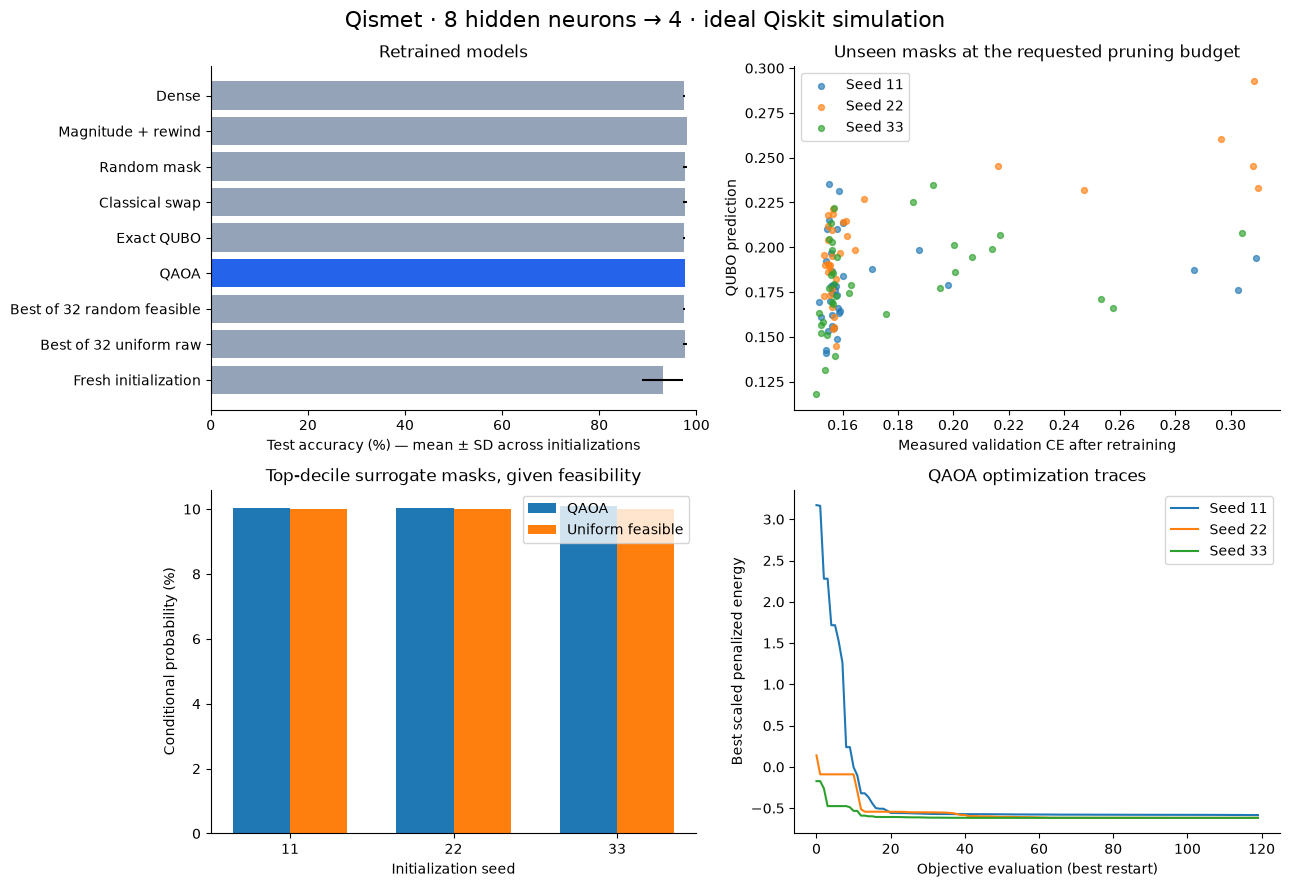

In [10]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
means = summary.test_accuracy_mean*100
axes[0,0].barh(means.index, means.values, xerr=summary.test_accuracy_sd.fillna(0)*100,
              color=['#2563eb' if x=='QAOA' else '#94a3b8' for x in means.index])
axes[0,0].set(xlabel='Test accuracy (%) — mean ± SD across initializations',
              title='Retrained models', xlim=(0,100))
axes[0,0].invert_yaxis()
for r in runs:
    audit = r['labels'].query("split == 'audit' and kept == @keep")
    axes[0,1].scatter(audit.val_loss, audit.predicted_val_loss, s=18, alpha=.65,
                      label=f"Seed {r['quality']['seed']}")
axes[0,1].set(xlabel='Measured validation CE after retraining', ylabel='QUBO prediction',
              title='Unseen masks at the requested pruning budget')
axes[0,1].legend()
xx = np.arange(len(runs)); width=.35
axes[1,0].bar(xx-width/2, diagnostics.QAOA_top10_given_feasible*100, width, label='QAOA')
axes[1,0].bar(xx+width/2, diagnostics.uniform_top10_given_feasible*100, width, label='Uniform feasible')
axes[1,0].set(xticks=xx, xticklabels=INITIALIZATION_SEEDS, xlabel='Initialization seed',
              ylabel='Conditional probability (%)', title='Top-decile surrogate masks, given feasibility')
axes[1,0].legend()
for r in runs:
    best = min(r['qaoa']['optimizer_records'], key=lambda o:o['best_scaled_expectation'])
    axes[1,1].plot(np.minimum.accumulate(best['scaled_trace']), label=f"Seed {r['quality']['seed']}")
axes[1,1].set(xlabel='Objective evaluation (best restart)', ylabel='Best scaled penalized energy',
              title='QAOA optimization traces')
axes[1,1].legend()
fig.suptitle(f'Qismet · {HIDDEN} hidden neurons → {keep} · ideal Qiskit simulation', fontsize=16)
fig.tight_layout()
fig.savefig(RESULT_DIR / 'experiment_summary.png', dpi=160, bbox_inches='tight')
plt.show()

### Interpretation and limits

The report below is generated from the executed results. Accuracy differences here are descriptive,
not significance tests. A successful pipeline does not establish quantum advantage, prove the
lottery-ticket hypothesis, or guarantee the same outcome for other networks or data.
If the quadratic surrogate ranks masks poorly, improving the optimizer cannot repair that mismatch.
If QAOA's conditional low-cost probability is near uniform, selecting a good mask from many shots
is largely best-of-random search. A cardinality-preserving mixer and a surrogate fitted specifically
within the pruning budget are reasonable future experiments, not changes made after seeing test scores.

In [11]:
qacc = summary.loc['QAOA','test_accuracy_mean']
dacc = summary.loc['Dense','test_accuracy_mean']
racc = summary.loc['Random mask','test_accuracy_mean']
bacc = summary.loc[f'Best of {SHOTS} random feasible','test_accuracy_mean']
eacc = summary.loc['Exact QUBO','test_accuracy_mean']
freshacc = summary.loc['Fresh initialization','test_accuracy_mean']
spearman = diagnostics.feasible_audit_Spearman.mean()
topmass = diagnostics.QAOA_top10_given_feasible.mean()
uniformmass = diagnostics.uniform_top10_given_feasible.mean()
report = f"""# Executed Qismet experiment

Completed all five milestones on a 2→8→2 PyTorch model using a local Qiskit simulator.
Across {len(runs)} fixed initializations on one fixed split, after {PRUNING_PERCENTAGE}% hidden-neuron pruning:

| Method | Mean test accuracy |
|---|---:|
| Dense | {dacc:.2%} |
| QAOA selected + rewind | {qacc:.2%} |
| Single random mask + rewind | {racc:.2%} |
| Best of {SHOTS} random feasible + rewind | {bacc:.2%} |
| Exact surrogate optimum + rewind | {eacc:.2%} |
| Fresh initialization, same width | {freshacc:.2%} |

The selected sparse model has {int(summary.loc['QAOA','parameters'])} parameters versus
{int(summary.loc['Dense','parameters'])} in the dense model.
Mean held-out within-budget Spearman correlation: **{spearman:.3f}**.
QAOA's mean probability of a top-decile surrogate mask, conditional on feasibility:
**{topmass:.2%}**, versus **{uniformmass:.2%}** for uniform feasible sampling.

This demonstrates an executed pruning/rewinding/QUBO/QAOA pipeline. It does not establish
quantum advantage or superiority over random/classical pruning. Interpret the accuracy table
together with the surrogate holdout metrics and sampling diagnostics. Test data did not guide
surrogate fitting, optimizer settings, or mask selection.

Defaults: {EPOCHS} full-batch Adam steps, learning rate 0.03; seeds {INITIALIZATION_SEEDS};
two QAOA layers; three COBYLA starts; at most 120 objectives/start; {SHOTS} final shots.
Each initialization uses 128 fit-mask retrainings plus 48 audit-mask retrainings at the default
50% pruning budget. This is expensive label collection, not a speedup demonstration.
"""
display(Markdown(report))
(RESULT_DIR / 'RESULTS.md').write_text(report, encoding='utf-8')
config = {'hidden': HIDDEN, 'pruning_percentage': PRUNING_PERCENTAGE, 'epochs': EPOCHS,
          'seeds': INITIALIZATION_SEEDS, 'shots': SHOTS, 'versions': VERSIONS,
          'python': sys.version, 'data_seed': 2026, 'data_samples': 1500}
(RESULT_DIR / 'run_config.json').write_text(json.dumps(config, indent=2))

# Executed Qismet experiment

Completed all five milestones on a 2→8→2 PyTorch model using a local Qiskit simulator.
Across 3 fixed initializations on one fixed split, after 50% hidden-neuron pruning:

| Method | Mean test accuracy |
|---|---:|
| Dense | 97.44% |
| QAOA selected + rewind | 97.67% |
| Single random mask + rewind | 97.67% |
| Best of 32 random feasible + rewind | 97.44% |
| Exact surrogate optimum + rewind | 97.44% |
| Fresh initialization, same width | 93.11% |

The selected sparse model has 22 parameters versus
42 in the dense model.
Mean held-out within-budget Spearman correlation: **0.427**.
QAOA's mean probability of a top-decile surrogate mask, conditional on feasibility:
**10.06%**, versus **10.00%** for uniform feasible sampling.

This demonstrates an executed pruning/rewinding/QUBO/QAOA pipeline. It does not establish
quantum advantage or superiority over random/classical pruning. Interpret the accuracy table
together with the surrogate holdout metrics and sampling diagnostics. Test data did not guide
surrogate fitting, optimizer settings, or mask selection.

Defaults: 200 full-batch Adam steps, learning rate 0.03; seeds [11, 22, 33];
two QAOA layers; three COBYLA starts; at most 120 objectives/start; 32 final shots.
Each initialization uses 128 fit-mask retrainings plus 48 audit-mask retrainings at the default
50% pruning budget. This is expensive label collection, not a speedup demonstration.


454

### What this executed run supports

The QAOA-selected four-neuron networks retained the dense model's accuracy on this split,
but **random pruning achieved the same mean test accuracy (97.67%)**. Magnitude pruning
averaged 98.00%, and classical swap search averaged 97.67%. These small differences are
descriptive; no statistical superiority is established.

The quadratic approximation has limited predictive quality at the requested pruning budget:
held-out-mask R² values are **−0.262, 0.300, and −0.122**. Two are negative. The mean
rank correlation is 0.427. QAOA's conditional top-decile probability is **10.06%**, against
10.00% for uniform feasible masks, so it learns cardinality much more strongly than good-mask ranking.

All nine COBYLA restarts reached the declared evaluation limit; the result is the best observed
within that budget, not a claim of optimizer convergence. The next research steps are to improve
the surrogate and evaluate a cardinality-preserving mixer under a new, predeclared protocol.


## References and reproducibility

- [Frankle & Carbin: The Lottery Ticket Hypothesis](https://arxiv.org/abs/1803.03635).
- [IBM Qiskit: Quantum approximate optimization algorithm](https://quantum.cloud.ibm.com/docs/en/tutorials/quantum-approximate-optimization-algorithm).
- [IBM Qiskit: SparsePauliOp](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.SparsePauliOp).
- [PyTorch: Module and state_dict](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html).

See `results/` for every fitting/audit mask label, all QAOA sample counts and optimizer traces,
QUBO coefficients, original initialization checkpoints, selected subnetworks, metrics and configuration.
The `.py` helpers are convenience copies; the notebook itself includes the implementations.